# Fase 2 — Replicación y traslado
**Proyecto Integrador · Deep Learning · Universidad Externado de Colombia**  
**Autor:** Nelson Andrey García Patarroyo


**Objetivo:** replicar de forma reducida el método del artículo, trasladar RoBERTa-BNE al dataset colombiano y comparar el resultado con TF-IDF + Regresión Logística.

### Antes de ejecutar
1. En Colab, selecciona **Entorno de ejecución → Cambiar tipo de entorno de ejecución → T4 GPU**.
2. Sube `fake_news_dataset.csv` (base colombiana).
3. Para ejecutar también la replicación del artículo, sube además el CSV original de Kaggle con columnas de etiqueta, título y descripción, y activa `RUN_REPLICATION = True` en la sección 3.
4. Ejecuta **Entorno de ejecución → Ejecutar todo**. Si no tienes el CSV original, la parte colombiana puede ejecutarse sin detenerse.

Esta versión reduce el entrenamiento a dos estrategias comparables, un máximo de cuatro épocas y una sola semilla final. La replicación sobre el conjunto original utiliza una muestra de 1.500 registros y una época. Estas reducciones deben declararse en el informe; los resultados no se presentan como reproducción exacta de las cifras del artículo.


In [1]:
import os, sys, json, copy, time, random, re, subprocess, warnings, shutil
from pathlib import Path

def ensure(pip_name, import_name):
    # Solo instala lo que falte: NO se actualizan paquetes que Colab ya trae (evita conflictos de versiones)
    try:
        __import__(import_name)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name], check=True)

if os.environ.get("SKIP_INSTALL") != "1":
    for _pip, _imp in [("transformers>=4.40,<5", "transformers"), ("scikit-learn", "sklearn"), ("pandas", "pandas"), ("matplotlib", "matplotlib")]:
        ensure(_pip, _imp)

import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
import transformers, sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, matthews_corrcoef, confusion_matrix)
warnings.filterwarnings("ignore")

# ---------------- Configuración (todo fijo y registrado) ----------------
MODEL_ID    = os.environ.get("MODEL_ID_OVERRIDE", "IsGarrido/roberta-base-bne")  # RoBERTa-BNE (BSC), el mejor del artículo. PlanTL-GOB-ES/roberta-base-bne fue retirado de HF (jul-2025); copia comunitaria verificada (SHA256 2bb8e5dc… y ejemplo fill-mask del model card)
SEED_COL    = 42     # semilla de la Fase 1 (partición y CV colombianos)
SEED_REPL   = 16     # semilla del artículo
MAX_LEN     = 128    # artículo: 128 tokens (RoBERTa)
BATCH       = 16     # artículo: 16
DROPOUT     = 0.15   # artículo: 0.15
WEIGHT_DECAY = 0.001 # artículo: L2 = 0.001
CLIP_NORM   = 1.0

QUICK = os.environ.get("QUICK") == "1"          # solo para pruebas internas del código
REPL_TRAIN_SIZE = 200 if QUICK else 1500       # registros de entrenamiento en la replicación reducida (None = todos)
REPL_EPOCHS     = 1   if QUICK else 1           # artículo: 10 épocas + CV 5-fold (no viable en Colab T4 gratis)
MAX_EPOCHS      = 2   if QUICK else 4          # máximo de épocas en el traslado a Colombia
PATIENCE        = 2                              # parada temprana por val_loss
FINAL_SEEDS     = [42] if QUICK else [42]
N_BOOT          = 50  if QUICK else 500

DEVICE  = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"
OUT = Path("resultados_fase2"); OUT.mkdir(exist_ok=True)
T0 = time.time()

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

ENV = dict(torch=torch.__version__, transformers=transformers.__version__, sklearn=sklearn.__version__,
           device=DEVICE, gpu=(torch.cuda.get_device_name(0) if USE_AMP else None), model_id=MODEL_ID)
print(ENV)
if DEVICE == "cpu" and not QUICK:
    print("ATENCIÓN: no hay GPU. Activa GPU en Colab (Entorno de ejecución → Cambiar tipo).")

def get_file(descripcion, default):
    p = Path(default)
    if p.exists():
        return p
    try:
        from google.colab import files
        print("Sube", descripcion)
        up = files.upload()
        if not up:
            raise FileNotFoundError("No se subió ningún archivo. Vuelve a ejecutar la celda y selecciona el archivo.")
        return Path(next(iter(up)))
    except ImportError:
        raise FileNotFoundError(f"No encuentro {default}. Descarga {descripcion} y colócalo junto al notebook.")

def read_csv_robust(path, seps=(";", ",", "\t"), check=None):
    # Prueba varias codificaciones y separadores y exige que las columnas esperadas existan.
    last = None
    for enc in ["utf-8-sig", "utf-8", "latin-1"]:
        for sep in seps:
            try:
                d = pd.read_csv(path, sep=sep, encoding=enc)
                d.columns = [str(c).replace("\ufeff", "").strip() for c in d.columns]
                d = d.loc[:, ~pd.Index(d.columns).str.match(r"^Unnamed")]
                if d.shape[1] > 1 and (check is None or check(d)):
                    return d
            except Exception as e:
                last = e
    raise ValueError(f"No pude leer {path} con las columnas esperadas. Último error: {last}")

def jdefault(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, np.ndarray): return o.tolist()
    return str(o)

{'torch': '2.11.0+cu130', 'transformers': '5.18.0', 'sklearn': '1.6.1', 'device': 'cuda', 'gpu': 'Tesla T4', 'model_id': 'IsGarrido/roberta-base-bne'}


## 1. Datos colombianos y línea base de la Fase 1
Se reconstruye **exactamente** la partición y la línea base de la primera entrega (TF-IDF 1–2-gramas + Regresión Logística, `class_weight='balanced'`, partición 80/20 estratificada con semilla 42, CV 5-fold). Si las cifras no coinciden con las de la Fase 1, el cuaderno muestra una advertencia: así se garantiza que la comparación es contra la misma referencia.

In [2]:
COL_PATH = get_file("fake_news_dataset.csv (dataset colombiano)", os.environ.get("COL_CSV", "fake_news_dataset.csv"))
df = read_csv_robust(COL_PATH, seps=(";", ",", "\t"), check=lambda d: {"fake_news", "titulo", "texto"} <= set(d.columns))
# fake_news: True = noticia VERDADERA, False = FALSA (verificado contra los enlaces de los fact-checkers)
df["y"] = df["fake_news"].astype(str).str.strip().str.lower().eq("true").astype(int)   # 1 = verdadera, 0 = falsa
if not (len(df) == 134 and (df.y == 0).sum() == 74 and (df.y == 1).sum() == 60):
    print(f"⚠ ADVERTENCIA: el CSV tiene {len(df)} filas ({(df.y == 0).sum()} falsas / {(df.y == 1).sum()} verdaderas); la Fase 1 usó 134 (74/60). Verifica que subiste el archivo correcto.")

df["text_raw"] = df["titulo"].fillna("").astype(str) + " " + df["texto"].fillna("").astype(str)   # entrada del Transformer
def clean_text(t):
    t = str(t).lower()
    t = re.sub(r"http\S+|www\.\S+", " ", t)
    t = re.sub(r"[^a-záéíóúñü0-9\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()
df["text_clean"] = df["text_raw"].apply(clean_text)                                            # entrada de la línea base

y_all = df.y.values
idx_all = np.arange(len(df))
tr_idx, te_idx = train_test_split(idx_all, test_size=0.2, stratify=y_all, random_state=SEED_COL)
if not (len(tr_idx) == 107 and len(te_idx) == 27):
    print(f"⚠ ADVERTENCIA: partición {len(tr_idx)}/{len(te_idx)}; la Fase 1 usó 107/27.")
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED_COL).split(tr_idx, y_all[tr_idx]))

def make_baseline():
    return Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2)),
                     ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED_COL))])

def metrics(y, p):
    return dict(accuracy=float(accuracy_score(y, p)), precision=float(precision_score(y, p, zero_division=0)),
                recall=float(recall_score(y, p, zero_division=0)), f1=float(f1_score(y, p, zero_division=0)),
                mcc=float(matthews_corrcoef(y, p)), cm=confusion_matrix(y, p, labels=[0, 1]).tolist())

# --- línea base: CV por fold (mismos folds que usará el Transformer) + test ---
Xc = df.text_clean.values
base_cv = []
for a, b in folds:
    m = make_baseline().fit(Xc[tr_idx[a]], y_all[tr_idx[a]])
    base_cv.append(metrics(y_all[tr_idx[b]], m.predict(Xc[tr_idx[b]])))
base = make_baseline().fit(Xc[tr_idx], y_all[tr_idx])
base_pred_te = base.predict(Xc[te_idx])
base_test = metrics(y_all[te_idx], base_pred_te)

cv_f1 = [r["f1"] for r in base_cv]
print(f"Línea base CV  F1 = {np.mean(cv_f1):.3f} ± {np.std(cv_f1):.3f}   (Fase 1: 0.639 ± 0.043)")
print(f"Línea base TEST F1 = {base_test['f1']:.3f}  acc = {base_test['accuracy']:.3f}  MCC = {base_test['mcc']:.3f}  cm = {base_test['cm']}")
if not (abs(base_test["f1"] - 0.455) < 0.0015 and base_test["cm"] == [[10, 5], [7, 5]]):
    print("⚠ ADVERTENCIA: la línea base recalculada aquí NO coincide con la de la Fase 1 (F1 test 0.455). Puede deberse a otra versión de scikit-learn o a un CSV distinto. El resto del notebook usa la línea base recalculada en ESTE entorno, así la comparación sigue siendo justa; reporta ambas cifras en el informe.")
if abs(np.mean(cv_f1) - 0.639) > 0.002:
    print("⚠ ADVERTENCIA: el F1 de CV de la línea base difiere de la Fase 1 (0.639 ± 0.043).")

# --- auditoría rápida de posibles atajos (para el informe y la Fase 3) ---
def ct(a, b):
    t = pd.crosstab(a, b)
    return {str(c): {str(i): int(v) for i, v in t[c].items()} for c in t.columns}
audit = {"medio_por_clase": ct(df["medio"].astype(str).str.strip(), df.y),
         "titulo_NP_por_clase": ct(df["titulo"].astype(str).str.strip().eq("NP"), df.y)}
print(pd.crosstab(df["medio"].astype(str).str.strip(), df.y).rename(columns={0: "falsa", 1: "verdadera"}))

Línea base CV  F1 = 0.639 ± 0.043   (Fase 1: 0.639 ± 0.043)
Línea base TEST F1 = 0.455  acc = 0.556  MCC = 0.086  cm = [[10, 5], [7, 5]]
y           falsa  verdadera
medio                       
Facebook       25          8
Instagram       3          5
Página web      8         20
Telegram        1          0
Twitter        37         27


## 2. Preparación del Transformer y estrategia de transferencia

Se comparan dos alternativas para evitar una matriz de experimentos demasiado costosa con solo 134 registros:

- **Extractor congelado:** se conservan los pesos del encoder preentrenado y solo se ajusta la cabeza de clasificación.
- **Fine-tuning completo:** se actualizan todos los parámetros de RoBERTa-BNE, siguiendo la estrategia principal del artículo con tasa de aprendizaje `1e-5`.

Se usa AdamW, ponderación de clases, longitud máxima de 128 tokens, batch de 16, clipping de gradiente y parada temprana por pérdida de validación. El máximo es de cuatro épocas por fold. La comparación mantiene los mismos folds que la línea base. La reducción busca que el notebook sea ejecutable en una GPU T4 sin multiplicar innecesariamente los entrenamientos.


In [3]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding, get_constant_schedule_with_warmup

def resolve_model_id():
    cands = [MODEL_ID] if os.environ.get("MODEL_ID_OVERRIDE") else [MODEL_ID, "Buzzeitor/roberta-base-bne"]
    err = None
    for c in cands:
        try:
            return c, AutoTokenizer.from_pretrained(c)
        except Exception as e:
            err = e
            print(f"No pude cargar {c}: {type(e).__name__}: {str(e)[:200]}")
    raise RuntimeError("No se pudo descargar RoBERTa-BNE de Hugging Face. Revisa que Colab tenga Internet y vuelve a ejecutar. Último error: " + str(err))

MODEL_ID, tok = resolve_model_id()
print("Modelo:", MODEL_ID)
collator = DataCollatorWithPadding(tok)

class DS(torch.utils.data.Dataset):
    def __init__(self, texts, labels):
        self.enc = tok([str(t) for t in texts], truncation=True, max_length=MAX_LEN)
        self.labels = [int(v) for v in labels]
    def __len__(self): return len(self.labels)
    def __getitem__(self, i):
        d = {k: v[i] for k, v in self.enc.items()}
        d["labels"] = self.labels[i]
        return d

def make_loader(texts, labels, shuffle, seed=0, bs=BATCH):
    g = torch.Generator(); g.manual_seed(seed)
    return torch.utils.data.DataLoader(DS(texts, labels), batch_size=bs, shuffle=shuffle, collate_fn=collator, generator=g)

CONFIGS = {
    # Alternativa 1: solo se entrena la cabeza de clasificación.
    "congelado": dict(mode="frozen", lr_head=5e-4, lr_enc=0.0, top=0),
    # Alternativa 2: fine-tuning completo, como en el artículo (lr=1e-5).
    "completo_1e-5": dict(mode="full", lr_head=1e-5, lr_enc=1e-5, top=None),
}

def build_model(cfg, seed):
    set_seed(seed)
    m = AutoModelForSequenceClassification.from_pretrained(MODEL_ID, num_labels=2,
            hidden_dropout_prob=DROPOUT, classifier_dropout=DROPOUT)
    enc_params = []
    if cfg["mode"] == "frozen":
        for p in m.base_model.parameters(): p.requires_grad = False
    elif cfg["mode"] == "partial":
        for p in m.base_model.parameters(): p.requires_grad = False
        for layer in m.base_model.encoder.layer[-cfg["top"]:]:
            for p in layer.parameters(): p.requires_grad = True
            enc_params += list(layer.parameters())
    else:
        enc_params = list(m.base_model.parameters())
    groups = [{"params": list(m.classifier.parameters()), "lr": cfg["lr_head"]}]
    if enc_params: groups.append({"params": enc_params, "lr": cfg["lr_enc"]})
    return m.to(DEVICE), groups

def class_weights(y):
    c = np.bincount(np.asarray(y), minlength=2)
    return torch.tensor(len(y) / (2.0 * c), dtype=torch.float, device=DEVICE)   # mismo criterio que class_weight='balanced'

def evaluate(model, dl, cw):
    model.eval(); lossf = torch.nn.CrossEntropyLoss(weight=cw, reduction="sum")
    tot, wsum, preds, probs = 0.0, 0.0, [], []
    with torch.no_grad():
        for b in dl:
            b = {k: v.to(DEVICE) for k, v in b.items()}; y = b.pop("labels")
            with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
                logits = model(**b).logits.float()
            tot += lossf(logits, y).item(); wsum += cw[y].sum().item()
            preds += logits.argmax(-1).tolist(); probs += torch.softmax(logits, -1)[:, 1].tolist()
    return tot / wsum, np.array(preds), np.array(probs)

def fit(cfg, tr_texts, tr_y, va_texts=None, va_y=None, epochs=MAX_EPOCHS, patience=PATIENCE, seed=SEED_COL, restore_best=True, verbose=False):
    model, groups = build_model(cfg, seed)
    cw = class_weights(tr_y)
    dl_tr = make_loader(tr_texts, tr_y, True, seed)
    dl_va = make_loader(va_texts, va_y, False, bs=64) if va_texts is not None else None
    opt = torch.optim.AdamW(groups, weight_decay=WEIGHT_DECAY)
    sch = get_constant_schedule_with_warmup(opt, min(len(dl_tr), 50))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    lossf = torch.nn.CrossEntropyLoss(weight=cw)
    hist, best, bad = [], dict(loss=float("inf"), epoch=0, state=None, preds=None, probs=None), 0
    trainable = [p for p in model.parameters() if p.requires_grad]
    for ep in range(1, epochs + 1):
        model.train()
        if cfg["mode"] == "frozen": model.base_model.eval()      # encoder congelado: sin dropout en el encoder
        tl, nb, gn = 0.0, 0, []
        for b in dl_tr:
            b = {k: v.to(DEVICE) for k, v in b.items()}; y = b.pop("labels")
            opt.zero_grad(set_to_none=True)
            with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
                logits = model(**b).logits
            loss = lossf(logits.float(), y)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            gn.append(float(torch.nn.utils.clip_grad_norm_(trainable, CLIP_NORM)))   # norma ANTES de recortar
            scaler.step(opt); scaler.update(); sch.step()
            tl += loss.item(); nb += 1
        rec = dict(epoch=ep, train_loss=tl / nb, grad_norm=float(np.mean(gn)))
        if dl_va is not None:
            vloss, vp, vprob = evaluate(model, dl_va, cw)
            mm = metrics(va_y, vp)
            rec.update(val_loss=vloss, val_f1=mm["f1"], val_accuracy=mm["accuracy"], val_mcc=mm["mcc"])
            if vloss < best["loss"] - 1e-4:
                best = dict(loss=vloss, epoch=ep, preds=vp, probs=vprob,
                            state={k: v.detach().cpu().clone() for k, v in model.state_dict().items()}); bad = 0
            else:
                bad += 1
        hist.append(rec)
        if verbose: print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in rec.items()}, flush=True)
        if dl_va is not None and patience and bad >= patience: break
    if dl_va is not None and restore_best and best["state"] is not None:
        model.load_state_dict(best["state"])
    return model, hist, best

def predict(model, texts, labels, bs=64):
    cw = torch.ones(2, device=DEVICE)
    _, p, pr = evaluate(model, make_loader(texts, labels, False, bs=bs), cw)
    return p, pr

def free(*objs):
    for o in objs: del o
    import gc; gc.collect()
    if USE_AMP: torch.cuda.empty_cache()

# --- cuánto del texto colombiano excede 128 tokens (se trunca) ---
lens = [len(x) for x in tok(df.text_raw.tolist(), truncation=False)["input_ids"]]
trunc_share = float(np.mean(np.array(lens) > MAX_LEN))
print(f"Textos colombianos que superan {MAX_LEN} tokens (se truncan): {trunc_share:.1%}   |  mediana = {int(np.median(lens))} tokens")

# --- parámetros entrenables por configuración ---
param_info = {}
for name, cfg in CONFIGS.items():
    m, g = build_model(cfg, SEED_COL)
    tot = sum(p.numel() for p in m.parameters()); trn = sum(p.numel() for p in m.parameters() if p.requires_grad)
    param_info[name] = dict(total=tot, entrenables=trn, pct=100 * trn / tot)
    print(f"{name:16s} entrenables = {trn:>12,d} de {tot:,d} ({100*trn/tot:.2f} %)")
    free(m)

config.json:   0%|          | 0.00/613 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.39k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/851k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/509k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.21M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/957 [00:00<?, ?B/s]

... (8 outputs left out)

congelado        entrenables =      592,130 de 124,644,866 (0.48 %)


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: IsGarrido/roberta-base-bne
Key                        | Status     | 
---------------------------+------------+-
lm_head.decoder.weight     | UNEXPECTED | 
lm_head.decoder.bias       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


completo_1e-5    entrenables =  124,644,866 de 124,644,866 (100.00 %)


## 3. Replicación del método sobre el conjunto original (versión reducida)
**Qué se replica:** fine-tuning completo de RoBERTa-BNE con los hiperparámetros del artículo (lr 1e-5, 128 tokens, batch 16, dropout 0.15, L2 0.001, semilla 16), partición 80/20 estratificada, y evaluación con Accuracy / Precision / Recall / F1 / MCC sobre el **20 % de test completo**.

**Qué se reduce y por qué:** el artículo entrena 10 épocas con CV de 5 folds sobre ~46.000 noticias (≈50 ciclos completos de entrenamiento). Con una GPU T4 de Colab eso no es viable en tiempo de sesión, y la guía exige ser ejecutable con los recursos disponibles. Aquí se usa **una sola partición de validación (10 % del entrenamiento)**, `REPL_TRAIN_SIZE` registros de entrenamiento estratificados y `REPL_EPOCHS` épocas. El **test es el 20 % completo** y no se submuestrea, de modo que la métrica es comparable con la del artículo.

**Supuestos no verificables del artículo:** el texto de entrada se arma como `Titulo + " " + Descripcion` (el artículo lista ambos campos pero no el formato exacto); el artículo no reporta *scheduler*, *warm-up* ni *clipping*.

In [4]:
RUN_REPLICATION = True  # Intenta replicar el artículo con una muestra reducida; si falta el CSV, se informa y sigue con Colombia.
PAPER = dict(accuracy=0.986, precision=0.985, recall=0.991, f1=0.988, mcc=0.971)   # Tabla 6 del artículo, RoBERTa-BNE
REP = dict(ok=False, error=None)
rep_model, p_zs_all, p_zs_te, zs_test, zs_all = None, None, None, None, None

import unicodedata
def _norm(s):
    return "".join(ch for ch in unicodedata.normalize("NFD", str(s).lower()) if unicodedata.category(ch) != "Mn").strip()
def find_cols(d):
    n = {_norm(c): c for c in d.columns}
    lab = next((n[k] for k in n if k in ("label", "etiqueta", "clase")), None)
    tit = next((n[k] for k in n if k.startswith("titul") or k in ("title", "headline")), None)
    des = next((n[k] for k in n if k.startswith("descrip") or k in ("texto", "text", "body", "cuerpo")), None)
    return (lab, tit, des) if (lab and tit and des) else None

if not RUN_REPLICATION:
    REP["error"] = "omitida por el usuario"
else:
    try:
        t_stage = time.time()
        ORIG_PATH = get_file(
            "CSV original de Kaggle (noticias políticas españolas; debe incluir etiqueta, título y descripción)",
            os.environ.get("REPL_CSV", "spanish_political_fake_news.csv")
        )
        orig = read_csv_robust(ORIG_PATH, seps=(",", ";", "\t"), check=lambda d: find_cols(d) is not None)
        c_lab, c_tit, c_des = find_cols(orig)
        raw = orig[c_lab]
        if raw.dtype == object:
            mp = {"1": 1, "0": 0, "1.0": 1, "0.0": 0, "true": 1, "false": 0, "real": 1, "fake": 0, "verdadera": 1, "falsa": 0, "verdadero": 1, "falso": 0}
            orig["y"] = raw.astype(str).str.strip().str.lower().map(mp)
        else:
            orig["y"] = raw
        orig = orig.dropna(subset=["y"]).copy(); orig["y"] = orig["y"].astype(int)   # artículo: 1 = real, 0 = fake (igual que nuestra convención)
        if set(orig.y.unique()) != {0, 1}:
            raise ValueError(f"La columna {c_lab} debería tener solo 0/1; valores encontrados: {sorted(orig.y.unique())[:10]}")
        orig["text"] = orig[c_tit].fillna("").astype(str) + " " + orig[c_des].fillna("").astype(str)
        print("Dataset original:", orig.shape, "| columnas usadas:", (c_lab, c_tit, c_des), "| % reales =", f"{orig.y.mean():.1%}", "(artículo: 52 %)")
        REP.update(n_total=len(orig), pct_label1=float(orig.y.mean()), n_label1=int(orig.y.sum()),
                   n_duplicados_texto=int(orig.duplicated(subset=["text"]).sum()), n_duplicados_titulo=int(orig.duplicated(subset=[c_tit]).sum()))
        print(f"% Label=1: {REP['pct_label1']:.2%} | duplicados por texto (título+descripción): {REP['n_duplicados_texto']} | por título: {REP['n_duplicados_titulo']}  (se usan tal cual, sin filtrar)")

        pool, test_o = train_test_split(orig, test_size=0.2, stratify=orig.y, random_state=SEED_REPL)
        if REPL_TRAIN_SIZE and REPL_TRAIN_SIZE < len(pool):
            pool = train_test_split(pool, train_size=REPL_TRAIN_SIZE, stratify=pool.y, random_state=SEED_REPL)[0]
        tr_o, va_o = train_test_split(pool, test_size=0.1, stratify=pool.y, random_state=SEED_REPL)
        print(f"Replicación → train {len(tr_o)} | val {len(va_o)} | test {len(test_o)} (20 % completo)")

        cfg_paper = dict(mode="full", lr_head=1e-5, lr_enc=1e-5, top=None)
        rep_model, rep_hist, rep_best = fit(cfg_paper, tr_o.text.values, tr_o.y.values, va_o.text.values, va_o.y.values,
                                            epochs=REPL_EPOCHS, patience=0, seed=SEED_REPL, restore_best=True, verbose=True)
        p_o, _ = predict(rep_model, test_o.text.values, test_o.y.values)
        rep_test = metrics(test_o.y.values, p_o)

        cmp = pd.DataFrame({"artículo": PAPER, "replicación (reducida)": {k: rep_test[k] for k in PAPER}})
        cmp["Δ (rep − art.)"] = cmp["replicación (reducida)"] - cmp["artículo"]
        print(cmp.round(3))
        print("épocas ejecutadas:", len(rep_hist), "| mejor época por val_loss:", rep_best["epoch"])
        REP.update(ok=True, n_train=len(tr_o), n_val=len(va_o), n_test=len(test_o), epocas=REPL_EPOCHS, test=rep_test,
                   paper=PAPER, hist=rep_hist, minutos=(time.time() - t_stage) / 60)
        print(f"Tiempo replicación: {REP['minutos']:.1f} min")
    except Exception as e:
        import traceback; traceback.print_exc()
        REP["error"] = f"{type(e).__name__}: {e}"
        rep_model = None
        print("\n⚠ La replicación falló y se OMITE; el traslado a Colombia continúa. Error:", REP["error"])

Dataset original: (57231, 7) | columnas usadas: ('Label', 'Titulo', 'Descripcion') | % reales = 58.3% (artículo: 52 %)
% Label=1: 58.27% | duplicados por texto (título+descripción): 467 | por título: 5631  (se usan tal cual, sin filtrar)
Replicación → train 1350 | val 150 | test 11447 (20 % completo)


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: IsGarrido/roberta-base-bne
Key                        | Status     | 
---------------------------+------------+-
lm_head.decoder.weight     | UNEXPECTED | 
lm_head.decoder.bias       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'epoch': 1, 'train_loss': 0.6952, 'grad_norm': inf, 'val_loss': 0.6937, 'val_f1': 0.7342, 'val_accuracy': 0.58, 'val_mcc': 0.0}
           artículo  replicación (reducida)  Δ (rep − art.)
accuracy      0.986                   0.583          -0.403
precision     0.985                   0.583          -0.402
recall        0.991                   1.000           0.009
f1            0.988                   0.736          -0.252
mcc           0.971                   0.000          -0.971
épocas ejecutadas: 1 | mejor época por val_loss: 1
Tiempo replicación: 0.6 min


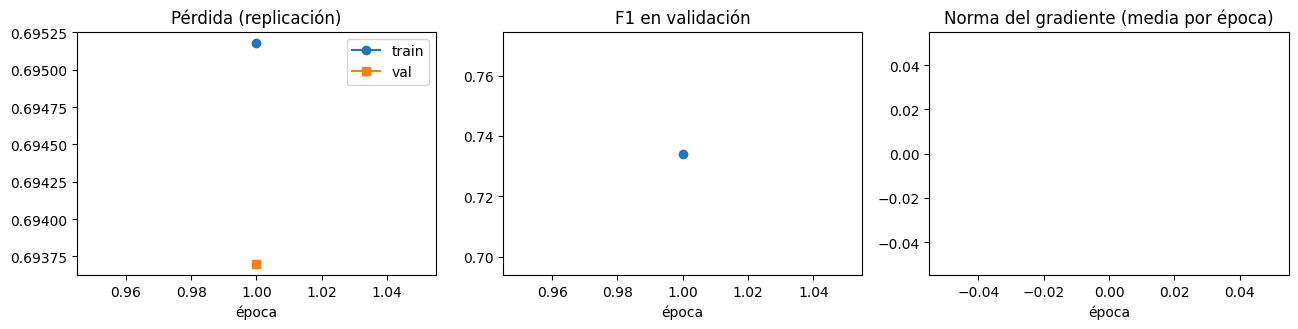

In [5]:
if REP["ok"]:
    # --- curvas de la replicación ---
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
    ep = [h["epoch"] for h in REP["hist"]]
    ax[0].plot(ep, [h["train_loss"] for h in REP["hist"]], "o-", label="train"); ax[0].plot(ep, [h["val_loss"] for h in REP["hist"]], "s-", label="val"); ax[0].set_title("Pérdida (replicación)"); ax[0].legend(); ax[0].set_xlabel("época")
    ax[1].plot(ep, [h["val_f1"] for h in REP["hist"]], "o-"); ax[1].set_title("F1 en validación"); ax[1].set_xlabel("época")
    ax[2].plot(ep, [h["grad_norm"] for h in REP["hist"]], "o-"); ax[2].set_title("Norma del gradiente (media por época)"); ax[2].set_xlabel("época")
    plt.tight_layout(); plt.savefig(OUT / "fig_replicacion_curvas.png", dpi=150); plt.show()
else:
    print("Replicación omitida o fallida: no hay curvas que graficar.")

## 4. Evaluación fuera de dominio (sin reentrenar)
El modelo replicado —entrenado con noticias españolas, en buena parte sintéticas— se evalúa **directamente** sobre las noticias colombianas. Es el análogo local de la prueba del artículo (98,6 % → 71 %): mide cuánto del conocimiento aprendido se transfiere *sin ver ningún dato colombiano*. Se reporta sobre los 27 registros de test y sobre los 134 (que el modelo nunca vio).

In [6]:
if REP["ok"] and rep_model is not None:
    p_zs_all, _ = predict(rep_model, df.text_raw.values, y_all)
    p_zs_te = p_zs_all[te_idx]
    zs_test = metrics(y_all[te_idx], p_zs_te); zs_all = metrics(y_all, p_zs_all)
    print("Fuera de dominio (sin reentrenar) — test 27 :", {k: round(v, 3) for k, v in zs_test.items() if k != "cm"}, zs_test["cm"])
    print("Fuera de dominio (sin reentrenar) — 134     :", {k: round(v, 3) for k, v in zs_all.items() if k != "cm"}, zs_all["cm"])
    print("Proporción de predicciones 'verdadera' en los 134:", f"{p_zs_all.mean():.1%}", "(real: 44.8 %)")
    rep_model = None
    import gc; gc.collect()
    if USE_AMP: torch.cuda.empty_cache()
else:
    print("Replicación omitida o fallida: se salta la evaluación fuera de dominio.")

Fuera de dominio (sin reentrenar) — test 27 : {'accuracy': 0.444, 'precision': 0.444, 'recall': 1.0, 'f1': 0.615, 'mcc': 0.0} [[0, 15], [0, 12]]
Fuera de dominio (sin reentrenar) — 134     : {'accuracy': 0.448, 'precision': 0.448, 'recall': 1.0, 'f1': 0.619, 'mcc': 0.0} [[0, 74], [0, 60]]
Proporción de predicciones 'verdadera' en los 134: 100.0% (real: 44.8 %)


## 5. Traslado a Colombia: comparación de transferencia (CV 5-fold)

Se comparan **extractor congelado** y **fine-tuning completo** usando los mismos cinco folds de entrenamiento que la línea base. La selección se realiza por F1 medio de validación cruzada, nunca mirando el test.

Con solo 107 registros de entrenamiento, las métricas por fold tienen alta variabilidad y deben interpretarse como evidencia exploratoria, no como una estimación precisa del desempeño poblacional.


In [7]:
t_stage = time.time()
texts_all = df.text_raw.values
cv_res = {}
for name, cfg in CONFIGS.items():
    recs = []
    for k, (a, b) in enumerate(folds):
        tri, vai = tr_idx[a], tr_idx[b]
        model, hist, best = fit(cfg, texts_all[tri], y_all[tri], texts_all[vai], y_all[vai], seed=SEED_COL)
        mm = metrics(y_all[vai], best["preds"])
        recs.append(dict(fold=k, best_epoch=best["epoch"], hist=hist, **mm))
        free(model, best)
    cv_res[name] = recs
    f1s = [r["f1"] for r in recs]
    print(f"{name:16s} CV F1 = {np.mean(f1s):.3f} ± {np.std(f1s):.3f} | mejor época por fold = {[r['best_epoch'] for r in recs]}")
print(f"{'línea base':16s} CV F1 = {np.mean(cv_f1):.3f} ± {np.std(cv_f1):.3f}")
print(f"Tiempo CV: {(time.time()-t_stage)/60:.1f} min")

rows = []
for name in CONFIGS:
    r = {"modelo": name}
    for mname in ["accuracy", "precision", "recall", "f1"]:
        v = [x[mname] for x in cv_res[name]]; r[mname] = f"{np.mean(v):.3f} ± {np.std(v):.3f}"
    rows.append(r)
r = {"modelo": "línea base (TF-IDF+LR)"}
for mname in ["accuracy", "precision", "recall", "f1"]:
    v = [x[mname] for x in base_cv]; r[mname] = f"{np.mean(v):.3f} ± {np.std(v):.3f}"
rows.append(r)
cv_table = pd.DataFrame(rows); print(cv_table.to_string(index=False)); cv_table.to_csv(OUT / "tabla_cv.csv", index=False)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: IsGarrido/roberta-base-bne
Key                        | Status     | 
---------------------------+------------+-
lm_head.decoder.weight     | UNEXPECTED | 
lm_head.decoder.bias       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: IsGarrido/roberta-base-bne
Key                        | Status     | 
---------------------------+------------+-
lm_head.decoder.weight     | UNEXPECTED | 
lm_head.decoder.bias       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: IsGarrido/roberta-base-bne
Key                        | Status     | 
---------------------------+------------+-
lm_head.decoder.weight     | UNEXPECTED | 
lm_head.decoder.bias       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (12 outputs left out)

[transformers] RobertaForSequenceClassification LOAD REPORT from: IsGarrido/roberta-base-bne
Key                        | Status     | 
---------------------------+------------+-
lm_head.decoder.weight     | UNEXPECTED | 
lm_head.decoder.bias       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: IsGarrido/roberta-base-bne
Key                        | Status     | 
---------------------------+------------+-
lm_head.decoder.weight     | UNEXPECTED | 
lm_head.decoder.bias       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


completo_1e-5    CV F1 = 0.473 ± 0.082 | mejor época por fold = [1, 1, 1, 4, 2]
línea base       CV F1 = 0.639 ± 0.043
Tiempo CV: 0.6 min
                modelo      accuracy     precision        recall            f1
             congelado 0.644 ± 0.067 0.660 ± 0.104 0.562 ± 0.212 0.566 ± 0.110
         completo_1e-5 0.403 ± 0.032 0.388 ± 0.037 0.624 ± 0.180 0.473 ± 0.082
línea base (TF-IDF+LR) 0.663 ± 0.059 0.628 ± 0.078 0.664 ± 0.084 0.639 ± 0.043


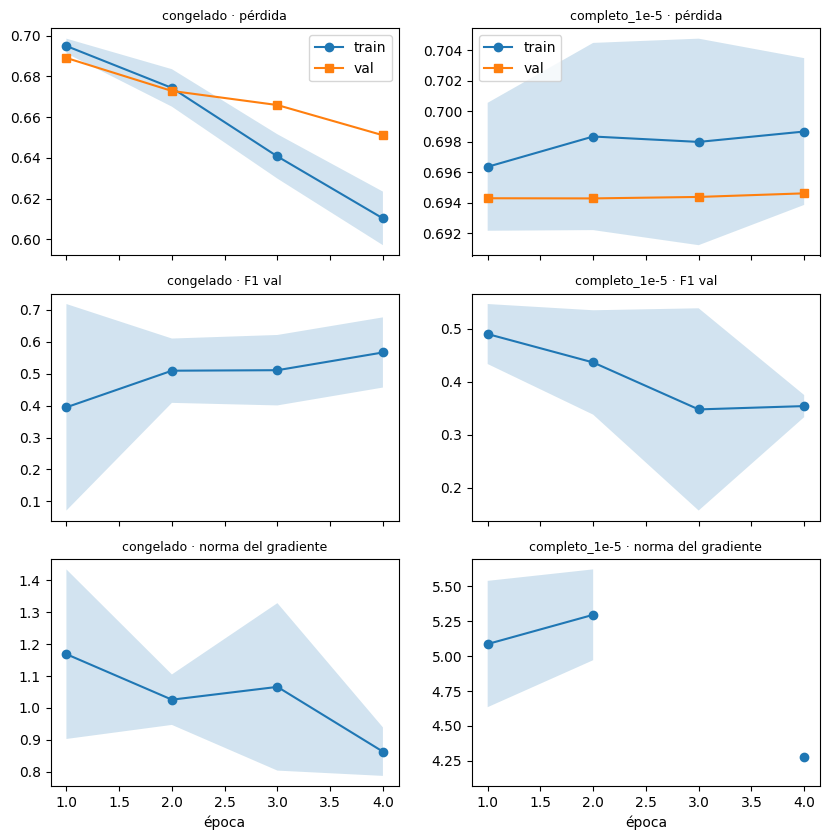

In [8]:
# --- curvas de entrenamiento/validación por configuración (media ± desv. entre folds) ---
def stack(recs, key):
    arr = np.full((len(recs), MAX_EPOCHS), np.nan)
    for i, r in enumerate(recs):
        v = [h[key] for h in r["hist"]]; arr[i, :len(v)] = v
    return arr
fig, axes = plt.subplots(3, len(CONFIGS), figsize=(4.2 * len(CONFIGS), 8.5), sharex=True)
for j, name in enumerate(CONFIGS):
    for key, row, ttl in [("train_loss", 0, "pérdida"), ("val_f1", 1, "F1 val"), ("grad_norm", 2, "norma del gradiente")]:
        A = stack(cv_res[name], key); x = np.arange(1, MAX_EPOCHS + 1)
        axes[row, j].plot(x, np.nanmean(A, 0), "o-", label="train" if key == "train_loss" else key)
        axes[row, j].fill_between(x, np.nanmean(A, 0) - np.nanstd(A, 0), np.nanmean(A, 0) + np.nanstd(A, 0), alpha=0.2)
        if key == "train_loss":
            V = stack(cv_res[name], "val_loss"); axes[row, j].plot(x, np.nanmean(V, 0), "s-", label="val")
            axes[row, j].legend()
        axes[row, j].set_title(f"{name} · {ttl}", fontsize=9)
        if row == 2: axes[row, j].set_xlabel("época")
plt.tight_layout(); plt.savefig(OUT / "fig_curvas_cv.png", dpi=150); plt.show()

## 6. Evaluación final y comparación contra la línea base

Cada configuración se reentrena sobre los 107 registros de entrenamiento usando la mediana de épocas óptimas observadas en CV y se evalúa una vez sobre los 27 registros de test. Se usa una semilla final para reducir tiempo; por ello, esta versión no estima variabilidad entre semillas. El bootstrap pareado del F1 es exploratorio y, dado el tamaño del test, debe interpretarse con cautela.


In [9]:
t_stage = time.time()
final = {}
for name, cfg in CONFIGS.items():
    ep_final = max(1, int(np.median([r["best_epoch"] for r in cv_res[name]])))
    per_seed = []
    for s in FINAL_SEEDS:
        model, hist, _ = fit(cfg, texts_all[tr_idx], y_all[tr_idx], epochs=ep_final, patience=0, seed=s)
        p, pr = predict(model, texts_all[te_idx], y_all[te_idx])
        per_seed.append(dict(seed=s, preds=p.tolist(), probs=pr.tolist(), hist=hist, **metrics(y_all[te_idx], p)))
        free(model)
    final[name] = dict(epochs=ep_final, runs=per_seed)
    f1s = [r["f1"] for r in per_seed]
    print(f"{name:16s} épocas={ep_final:2d} | TEST F1 por semilla = {[round(x,3) for x in f1s]} → {np.mean(f1s):.3f} ± {np.std(f1s):.3f}")
print(f"{'línea base':16s} TEST F1 = {base_test['f1']:.3f}")
print(f"Tiempo modelos finales: {(time.time()-t_stage)/60:.1f} min")

rows = []
for name in CONFIGS:
    r = {"modelo": name}
    for mname in ["accuracy", "precision", "recall", "f1", "mcc"]:
        v = [x[mname] for x in final[name]["runs"]]; r[mname] = f"{np.mean(v):.3f} ± {np.std(v):.3f}"
    rows.append(r)
r = {"modelo": "línea base (TF-IDF+LR)"}
for mname in ["accuracy", "precision", "recall", "f1", "mcc"]: r[mname] = f"{base_test[mname]:.3f}"
rows.append(r)
if zs_test is not None:
    r = {"modelo": "RoBERTa-BNE sin reentrenar (fuera de dominio)"}
    for mname in ["accuracy", "precision", "recall", "f1", "mcc"]: r[mname] = f"{zs_test[mname]:.3f}"
    rows.append(r)
test_table = pd.DataFrame(rows); print(test_table.to_string(index=False)); test_table.to_csv(OUT / "tabla_test.csv", index=False)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: IsGarrido/roberta-base-bne
Key                        | Status     | 
---------------------------+------------+-
lm_head.decoder.weight     | UNEXPECTED | 
lm_head.decoder.bias       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


congelado        épocas= 4 | TEST F1 por semilla = [0.611] → 0.611 ± 0.000


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: IsGarrido/roberta-base-bne
Key                        | Status     | 
---------------------------+------------+-
lm_head.decoder.weight     | UNEXPECTED | 
lm_head.decoder.bias       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


completo_1e-5    épocas= 1 | TEST F1 por semilla = [0.595] → 0.595 ± 0.000
línea base       TEST F1 = 0.455
Tiempo modelos finales: 0.1 min
                                       modelo      accuracy     precision        recall            f1            mcc
                                    congelado 0.481 ± 0.000 0.458 ± 0.000 0.917 ± 0.000 0.611 ± 0.000  0.079 ± 0.000
                                completo_1e-5 0.444 ± 0.000 0.440 ± 0.000 0.917 ± 0.000 0.595 ± 0.000 -0.032 ± 0.000
                       línea base (TF-IDF+LR)         0.556         0.500         0.417         0.455          0.086
RoBERTa-BNE sin reentrenar (fuera de dominio)         0.444         0.444         1.000         0.615          0.000


In [10]:
# --- configuración elegida por CV (NO por test) + bootstrap pareado contra la línea base ---
chosen = max(CONFIGS, key=lambda n: np.mean([r["f1"] for r in cv_res[n]]))
print("Configuración elegida por F1 medio en CV:", chosen)
yt = y_all[te_idx]
p_new = np.array(final[chosen]["runs"][0]["preds"]); p_base = np.array(base_pred_te)

def boot(n, seed=0):
    rng = np.random.default_rng(seed); d, a, b = [], [], []
    for _ in range(n):
        i = rng.integers(0, len(yt), len(yt))
        fa = f1_score(yt[i], p_new[i], zero_division=0); fb = f1_score(yt[i], p_base[i], zero_division=0)
        a.append(fa); b.append(fb); d.append(fa - fb)
    q = lambda x: [float(np.percentile(x, 2.5)), float(np.percentile(x, 97.5))]
    return dict(f1_transformer_ic95=q(a), f1_base_ic95=q(b), delta_media=float(np.mean(d)), delta_ic95=q(d), p_delta_mayor_0=float(np.mean(np.array(d) > 0)))
bt = boot(N_BOOT)
print(f"F1 test (semilla {FINAL_SEEDS[0]}): Transformer = {final[chosen]['runs'][0]['f1']:.3f} | línea base = {base_test['f1']:.3f}")
print("IC95% bootstrap F1  Transformer:", [round(x, 3) for x in bt["f1_transformer_ic95"]], "| línea base:", [round(x, 3) for x in bt["f1_base_ic95"]])
print(f"ΔF1 = {bt['delta_media']:+.3f}  IC95% = {[round(x,3) for x in bt['delta_ic95']]}  P(Δ>0) = {bt['p_delta_mayor_0']:.2f}")
print("Lectura: si el IC95% de ΔF1 incluye 0, con 27 registros NO hay evidencia suficiente para afirmar que un modelo supera al otro.")

# --- predicciones por registro (insumo para el análisis de fallas de la Fase 3) ---
pred_df = pd.DataFrame({"idx_original": te_idx, "y_real": yt, "pred_baseline": p_base})
for name in CONFIGS:
    pred_df[f"pred_{name}"] = final[name]["runs"][0]["preds"]; pred_df[f"prob_verdadera_{name}"] = final[name]["runs"][0]["probs"]
pred_df["pred_fuera_de_dominio"] = p_zs_te if p_zs_te is not None else np.nan
pred_df["medio"] = df.loc[te_idx, "medio"].astype(str).str.strip().values
pred_df.to_csv(OUT / "predicciones_test.csv", index=False)
print(pred_df.head())

Configuración elegida por F1 medio en CV: congelado
F1 test (semilla 42): Transformer = 0.611 | línea base = 0.455
IC95% bootstrap F1  Transformer: [0.412, 0.78] | línea base: [0.118, 0.698]
ΔF1 = +0.163  IC95% = [-0.085, 0.434]  P(Δ>0) = 0.86
Lectura: si el IC95% de ΔF1 incluye 0, con 27 registros NO hay evidencia suficiente para afirmar que un modelo supera al otro.
   idx_original  y_real  pred_baseline  pred_congelado  \
0            15       0              0               1   
1            71       1              0               1   
2            83       1              0               1   
3           127       0              0               1   
4           124       0              0               0   

   prob_verdadera_congelado  pred_completo_1e-5  prob_verdadera_completo_1e-5  \
0                  0.562552                   1                      0.506139   
1                  0.584686                   1                      0.506068   
2                  0.738622          

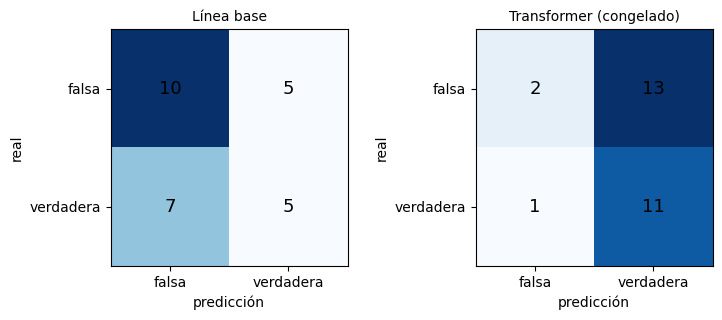

In [11]:
# --- matrices de confusión del test: línea base vs. configuración elegida ---
fig, ax = plt.subplots(1, 2, figsize=(7.5, 3.3))
for a, (ttl, p) in zip(ax, [("Línea base", p_base), (f"Transformer ({chosen})", p_new)]):
    cm = confusion_matrix(yt, p, labels=[0, 1]); a.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm): a.text(j, i, int(v), ha="center", va="center", fontsize=13)
    a.set_xticks([0, 1], ["falsa", "verdadera"]); a.set_yticks([0, 1], ["falsa", "verdadera"]); a.set_xlabel("predicción"); a.set_ylabel("real"); a.set_title(ttl, fontsize=10)
plt.tight_layout(); plt.savefig(OUT / "fig_matrices_confusion.png", dpi=150); plt.show()

## 7. Guardar resultados

Se guardan las métricas, historiales, configuración, predicciones por registro y gráficas. El archivo `resultados_fase2.zip` sirve como insumo para redactar el informe de la Segunda Entrega. No se deben completar cifras del informe hasta que la ejecución termine correctamente.


In [12]:
results = dict(
    entorno=ENV, tiempo_total_min=(time.time() - T0) / 60, quick=QUICK, replication_enabled=RUN_REPLICATION,
    config_global=dict(MODEL_ID=MODEL_ID, MAX_LEN=MAX_LEN, BATCH=BATCH, DROPOUT=DROPOUT, WEIGHT_DECAY=WEIGHT_DECAY, CLIP_NORM=CLIP_NORM,
                       SEED_COL=SEED_COL, SEED_REPL=SEED_REPL, MAX_EPOCHS=MAX_EPOCHS, PATIENCE=PATIENCE, FINAL_SEEDS=FINAL_SEEDS,
                       REPL_TRAIN_SIZE=REPL_TRAIN_SIZE, REPL_EPOCHS=REPL_EPOCHS, N_BOOT=N_BOOT),
    configs=CONFIGS, parametros=param_info, truncamiento_128_tokens=trunc_share, auditoria_atajos=audit,
    baseline=dict(cv=base_cv, test=base_test),
    replicacion=REP,
    fuera_de_dominio=dict(test27=zs_test, todos134=zs_all, prop_pred_verdadera=(float(p_zs_all.mean()) if p_zs_all is not None else None)),
    cv=cv_res, final=final, config_elegida_por_cv=chosen, bootstrap=bt,
)
(OUT / "resultados.json").write_text(json.dumps(results, default=jdefault, ensure_ascii=False, indent=1))
shutil.make_archive("resultados_fase2", "zip", OUT)
print("Guardado:", sorted(p.name for p in OUT.iterdir()))
print(f"Tiempo total: {(time.time()-T0)/60:.1f} min")
try:
    from google.colab import files; files.download("resultados_fase2.zip")
except ImportError:
    pass

Guardado: ['fig_curvas_cv.png', 'fig_matrices_confusion.png', 'fig_replicacion_curvas.png', 'predicciones_test.csv', 'resultados.json', 'tabla_cv.csv', 'tabla_test.csv']
Tiempo total: 1.6 min


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>